# Activity 2 code 

In [65]:
# These are all the libraries we will use 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch, HDBSCAN
from sklearn.metrics import (silhouette_score,calinski_harabasz_score,davies_bouldin_score,)

In [66]:
# We load the CSV file that holds the monthly records for all five payment systems.
df = pd.read_csv("../jopacc_system_month_november_2022_to_june_2026.csv")
df.head()

,report_month,report_year,report_quarter,system,users_total,transactions_total,transaction_value_jod,user_jordanian_count,user_non_jordanian_count,user_male_count,...,ach_usd_transaction_count,ach_usd_transaction_value,ach_eur_transaction_count,ach_eur_transaction_value,ach_gbp_transaction_count,ach_gbp_transaction_value,returned_cheque_count,returned_cheque_value_jod,returned_cheque_count_rate_pct,returned_cheque_value_rate_pct
0,2022-11,2022,Q4,CliQ,523000,985000,175000000,494200,24100,342500,...,0,0,0,0,0,0,0,0,0.0,0.0
1,2022-11,2022,Q4,JoMoPay,2020000,1260000,155000000,1760000,250000,1230000,...,0,0,0,0,0,0,0,0,0.0,0.0
2,2022-11,2022,Q4,eFAWATEERcom,3580000,3630000,848000000,0,0,0,...,0,0,0,0,0,0,0,0,0.0,0.0
3,2022-12,2022,Q4,CliQ,561000,1180000,209000000,529800,26300,365000,...,0,0,0,0,0,0,0,0,0.0,0.0
4,2022-12,2022,Q4,JoMoPay,2050000,1510000,188000000,1780000,250000,1230000,...,0,0,0,0,0,0,0,0,0.0,0.0


In [67]:
# Here we make sure that date time is actually date time and that if there is an error, it becomes NaT 
monthly = df.copy()
monthly["report_month"] = pd.to_datetime(monthly["report_month"],format="%Y-%m",errors="coerce")
# In this code, we group the records by the payment system and then we sort them based on their months.
monthly = monthly.sort_values(["system", "report_month"]).reset_index(drop=True)
monthly.head()

,report_month,report_year,report_quarter,system,users_total,transactions_total,transaction_value_jod,user_jordanian_count,user_non_jordanian_count,user_male_count,...,ach_usd_transaction_count,ach_usd_transaction_value,ach_eur_transaction_count,ach_eur_transaction_value,ach_gbp_transaction_count,ach_gbp_transaction_value,returned_cheque_count,returned_cheque_value_jod,returned_cheque_count_rate_pct,returned_cheque_value_rate_pct
0,2023-01-01,2023,Q1,ACH,0,875000,706000000,0,0,0,...,5236,31300000,253,2700000,34,190000,0,0,0.0,0.0
1,2023-02-01,2023,Q1,ACH,0,819000,639000000,0,0,0,...,4895,27700000,294,3200000,39,390000,0,0,0.0,0.0
2,2023-03-01,2023,Q1,ACH,0,920000,736000000,0,0,0,...,5502,33000000,267,2800000,34,360000,0,0,0.0,0.0
3,2023-04-01,2023,Q2,ACH,0,893000,673000000,0,0,0,...,5007,27000000,201,1600000,35,420000,0,0,0.0,0.0
4,2023-05-01,2023,Q2,ACH,0,931000,757000000,0,0,0,...,5716,37000000,387,2900000,47,520000,0,0,0.0,0.0


In [68]:
# Before we use the data we check it. We print how big the table is, then look for missing
# values, dates that could not be read, and any payment system that has the same month twice.
print("Number of rows:", len(monthly))
print("Number of columns:", len(monthly.columns))
print("Missing values:", monthly.isnull().sum().sum())
print("Invalid dates:", monthly["report_month"].isnull().sum())
print("Duplicate system-month records:", monthly.duplicated(["system", "report_month"]).sum())

# We also check that the report year matches the year inside the month column, and that the
# quarter column matches the quarter the month actually falls in.
wrong_year = monthly["report_year"] != monthly["report_month"].dt.year
correct_quarter = "Q" + monthly["report_month"].dt.quarter.astype(str)
wrong_quarter = monthly["report_quarter"] != correct_quarter
print("Incorrect year values:", wrong_year.sum())
print("Incorrect quarter values:", wrong_quarter.sum())

Number of rows: 214
Number of columns: 49
Missing values: 0
Invalid dates: 0
Duplicate system-month records: 0
Incorrect year values: 0
Incorrect quarter values: 0


In [69]:
# We here check for structural zeros. We do this by at first selecting all numerical columns 
numeric_columns = monthly.select_dtypes(include="number").columns

# Then we make an outer loop that goes through each system, where the inner loop checks every numerical column. If all values in a column is zero, we add them to zero columns.
for system in monthly["system"].unique():
    system_data = monthly[monthly["system"] == system]
    zero_columns = []

    for column in numeric_columns:
        if (system_data[column] == 0).all():
            zero_columns.append(column)

    print(system, "structure zero columns:")
    print(zero_columns)
    print()

ACH structure zero columns:
['users_total', 'user_jordanian_count', 'user_non_jordanian_count', 'user_male_count', 'user_female_count', 'user_age_under_30_count', 'user_age_31_50_count', 'user_age_51_plus_count', 'customer_individual_count', 'customer_legal_entity_count', 'wallet_individual_count', 'wallet_commercial_count', 'user_existing_count', 'user_new_count', 'tx_purchases_count', 'tx_money_transfers_count', 'tx_cash_out_count', 'tx_cash_in_count', 'value_purchases_jod', 'value_money_transfers_jod', 'value_cash_out_jod', 'value_cash_in_jod', 'on_us_money_transfer_count', 'off_us_money_transfer_count', 'on_us_money_transfer_value_jod', 'off_us_money_transfer_value_jod', 'billers_total', 'services_total', 'ef_cash_payment_count', 'ef_digital_payment_count', 'ef_cash_payment_value_jod', 'ef_digital_payment_value_jod', 'returned_cheque_count', 'returned_cheque_value_jod', 'returned_cheque_count_rate_pct', 'returned_cheque_value_rate_pct']

CliQ structure zero columns:
['wallet_indivi

In [70]:
# Every payment system is a different size, so comparing their raw numbers directly would only
# tell us which system is bigger. What we do instead is compare every month with the average of
# its own payment system.

# First we work out the average value of one transaction for each month.
monthly["average_transaction_value"] = (monthly["transaction_value_jod"] / monthly["transactions_total"])

# Then we take the mean of each payment system for the three things we care about.
average_transactions = monthly.groupby("system")["transactions_total"].transform("mean")
average_value = monthly.groupby("system")["transaction_value_jod"].transform("mean")
average_transaction_size = monthly.groupby("system")["average_transaction_value"].transform("mean")

# Dividing a month by its own system mean gives us the relative features. A value of 1.0 means
# the month sits on the historical average of that system, above 1.0 means it was busier than
# normal, and below 1.0 means it was quieter than normal.
monthly["relative_transaction_level"] = (monthly["transactions_total"] / average_transactions)
monthly["relative_value_level"] = (monthly["transaction_value_jod"] / average_value)
monthly["relative_average_transaction_value"] = (monthly["average_transaction_value"] / average_transaction_size)

# These three relative features are the only ones we send into the models.
features = monthly[["relative_transaction_level","relative_value_level","relative_average_transaction_value"]]
features.head()

,relative_transaction_level,relative_value_level,relative_average_transaction_value
0,0.899391,0.896177,0.996944
1,0.841830,0.811129,0.964031
2,0.945645,0.934259,0.988472
3,0.917892,0.854288,0.931189
4,0.956952,0.960915,1.004663


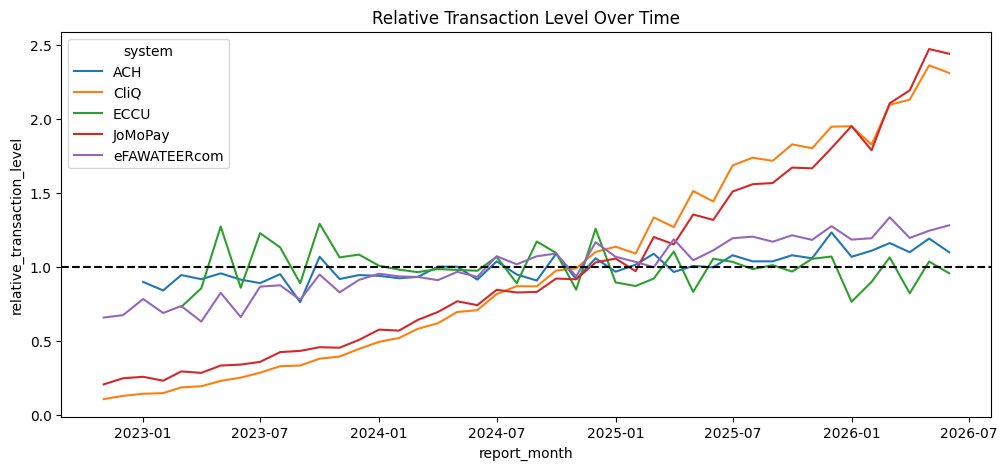

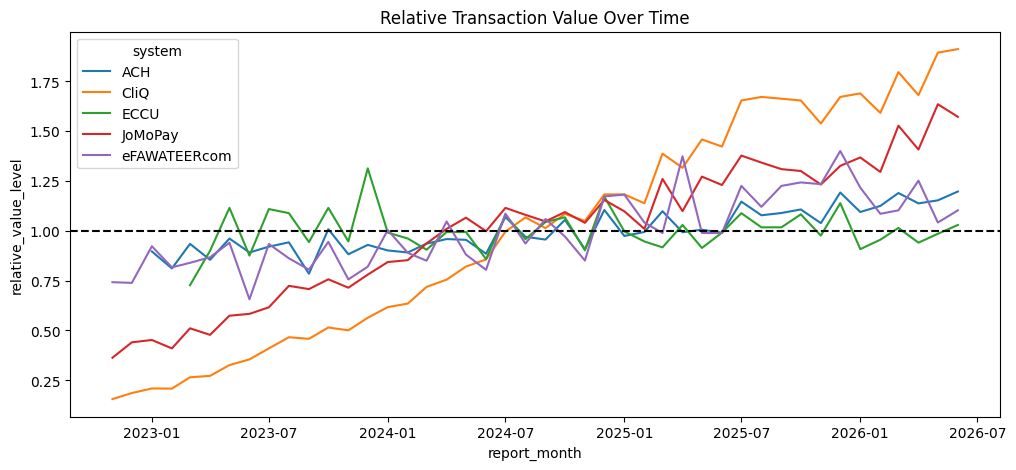

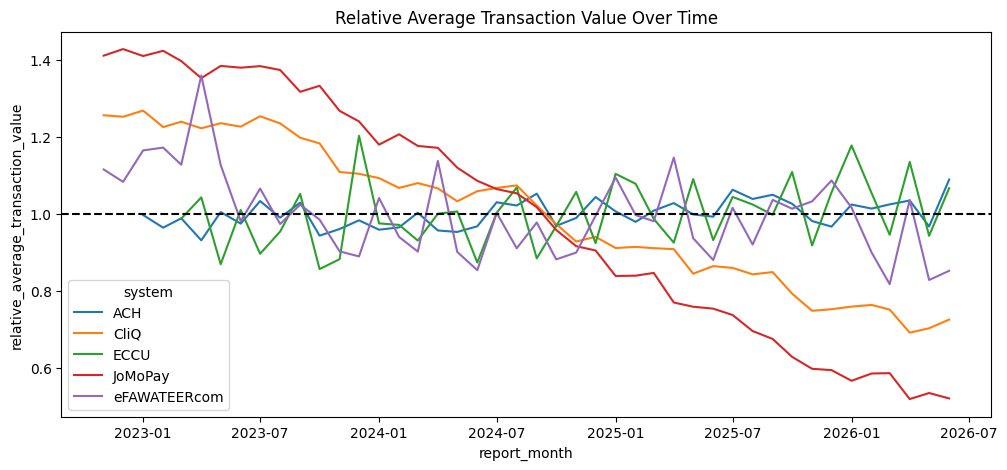

In [71]:
# Here we plot the three features we egnineered over time, with one line for each payment system.

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly,
    x="report_month",
    y="relative_transaction_level",
    hue="system"
)
plt.axhline(1, color="black", linestyle="--")
plt.title("Relative Transaction Level Over Time")
plt.show()

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly,
    x="report_month",
    y="relative_value_level",
    hue="system"
)
plt.axhline(1, color="black", linestyle="--")
plt.title("Relative Transaction Value Over Time")
plt.show()

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly,
    x="report_month",
    y="relative_average_transaction_value",
    hue="system"
)
plt.axhline(1, color="black", linestyle="--")
plt.title("Relative Average Transaction Value Over Time")
plt.show()

In [72]:
# The three features are on different ranges, so we standardise them before PCA.
# If we skip this step, the feature with the biggest numbers would end up controlling the result.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [73]:
# We apply PCA and keep two components.
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

pca_data = pd.DataFrame(pca_features, columns=["PC1", "PC2"])
pca_data.head()

,PC1,PC2
0,-0.318239,-0.249294
1,-0.448571,-0.579943
2,-0.158328,-0.197389
3,-0.161382,-0.616654
4,-0.145299,-0.069777


In [74]:
# Before we settle on a number of clusters, we try every k from 2 to 8 and score each one.
# Our data has no true label to check against, so we use internal measures instead.
k_results = []

for k in range(2, 9):
    trial_model = KMeans(n_clusters=k, init="k-means++", random_state=42)
    trial_labels = trial_model.fit_predict(pca_features)
    k_results.append([
        k,
        silhouette_score(pca_features, trial_labels),
        calinski_harabasz_score(pca_features, trial_labels),
        davies_bouldin_score(pca_features, trial_labels)
    ])

k_comparison = pd.DataFrame(k_results, columns=[
    "k", "silhouette", "calinski_harabasz", "davies_bouldin"
])
# Higher Silhouette and Calinski are better. lower Davies is better.
k_comparison.round(3)

,k,silhouette,calinski_harabasz,davies_bouldin
0,2,0.578,189.709,0.602
1,3,0.590,371.930,0.571
2,4,0.373,344.282,0.832
3,5,0.354,311.562,0.876
4,6,0.353,294.097,0.886
5,7,0.353,283.744,0.918
6,8,0.356,273.865,0.828


In [75]:
# We choose k by taking the highest silhouette score.
best_k = 3

In [76]:
# Now we run the five clustering algorithms on the same PCA values, so that the comparison
# between them stays fair. 

# K-means uses the k we chose above and works from cluster centres.
kmeans = KMeans(n_clusters=best_k, init="k-means++", random_state=42)
y_kmeans = kmeans.fit_predict(pca_features)

# Hierarchical clustering merges the closest groups together using Ward linkage.
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
y_hierarchical = hierarchical.fit_predict(pca_features)

# DBSCAN works through density.
dbscan = DBSCAN(eps=0.4, min_samples=4)
y_dbscan = dbscan.fit_predict(pca_features)

# BIRCH summarises the data into a tree first, which is what makes it fast on large datasets.
birch = Birch(n_clusters=3)
y_birch = birch.fit_predict(pca_features)

# HDBSCAN is DBSCAN across several density levels, and it keeps the clusters that stay stable.
hdbscan = HDBSCAN(min_cluster_size=5, copy=True)
y_hdbscan = hdbscan.fit_predict(pca_features)

In [77]:
# Here we compare the five algorithms using the three measures. Higher is better for
# silhouette and Calinski, while lower is better for Davies.
metrics_dict = {
    "algorithm": ["K-means", "Hierarchical", "DBSCAN", "BIRCH", "HDBSCAN"],
    "silhouette": [
        silhouette_score(pca_features, y_kmeans),
        silhouette_score(pca_features, y_hierarchical),
        silhouette_score(pca_features, y_dbscan),
        silhouette_score(pca_features, y_birch),
        silhouette_score(pca_features, y_hdbscan)
    ],
    "calinski_harabasz": [
        calinski_harabasz_score(pca_features, y_kmeans),
        calinski_harabasz_score(pca_features, y_hierarchical),
        calinski_harabasz_score(pca_features, y_dbscan),
        calinski_harabasz_score(pca_features, y_birch),
        calinski_harabasz_score(pca_features, y_hdbscan)
    ],
    "davies_bouldin": [
        davies_bouldin_score(pca_features, y_kmeans),
        davies_bouldin_score(pca_features, y_hierarchical),
        davies_bouldin_score(pca_features, y_dbscan),
        davies_bouldin_score(pca_features, y_birch),
        davies_bouldin_score(pca_features, y_hdbscan)
    ]
}

model_comparison = pd.DataFrame(metrics_dict)
model_comparison.round(3)

,algorithm,silhouette,calinski_harabasz,davies_bouldin
0,K-means,0.590,371.930,0.571
1,Hierarchical,0.578,290.077,0.509
2,DBSCAN,0.487,114.349,1.745
3,BIRCH,0.499,298.069,0.705
4,HDBSCAN,0.468,77.916,1.357


In [78]:
# We go with K-means. It has the highest silhouette, the highest Calinski and the
# Hierarchical has a slightly better Davies score, but it loses on everything else.
best_model_name = "K-means"
best_model = kmeans
cluster_labels = y_kmeans
# We add 1 to the labels so the clusters are numbered 1, 2 and 3 instead of starting at 0.
monthly["cluster"] = cluster_labels + 1
print("Best model:", best_model_name)

# Then we check how many months ended up inside each cluster.
monthly["cluster"].value_counts().sort_index()

Best model: K-means


cluster
1     28
2    150
3     36
Name: count, dtype: int64

In [79]:
# To understand what each cluster actually means, we create a new feature called activity level
cluster_profiles = monthly.groupby("cluster")[[
    "relative_transaction_level",
    "relative_value_level",
    "relative_average_transaction_value"
]].mean()

cluster_profiles["activity_score"] = (
    cluster_profiles["relative_transaction_level"]
    + cluster_profiles["relative_value_level"]
) / 2

cluster_profiles.round(3)

,relative_transaction_level,relative_value_level,relative_average_transaction_value,activity_score
cluster,,,,
1,1.848,1.517,0.703,1.683
2,0.994,1.016,0.993,1.005
3,0.365,0.530,1.261,0.448


In [80]:
# Now we name the clusters.
monthly["pattern"] = ""
monthly.loc[monthly["cluster"] == 1, "pattern"] = "High Activity"
monthly.loc[monthly["cluster"] == 2, "pattern"] = "Moderate Activity"
monthly.loc[monthly["cluster"] == 3, "pattern"] = "Low Activity"

cluster_profiles["pattern"] = ""
cluster_profiles.loc[1, "pattern"] = "High Activity"
cluster_profiles.loc[2, "pattern"] = "Moderate Activity"
cluster_profiles.loc[3, "pattern"] = "Low Activity"

cluster_profiles[["activity_score", "pattern"]].round(3)

,activity_score,pattern
cluster,,
1,1.683,High Activity
2,1.005,Moderate Activity
3,0.448,Low Activity


In [ ]:
# Here we look for unusual months. We measure how far every month sits from its own cluster
# centre, then inside each cluster we take the 95th percentile of those distances as a threshold. Any month that is farther than the 95th percentile is marked as unusual
all_distances = best_model.transform(pca_features)
distance_to_center = all_distances.min(axis=1)
monthly["stasis"] = "normal"

for cluster_number in [1, 2, 3]:
    cluster_rows = monthly["cluster"] == cluster_number
    threshold = np.percentile(distance_to_center[cluster_rows], 95)
    unusual_rows = cluster_rows & (distance_to_center > threshold)
    monthly.loc[unusual_rows, "stasis"] = "unusual"

monthly["stasis"].value_counts()

stasis
normal     202
unusual     12
Name: count, dtype: int64

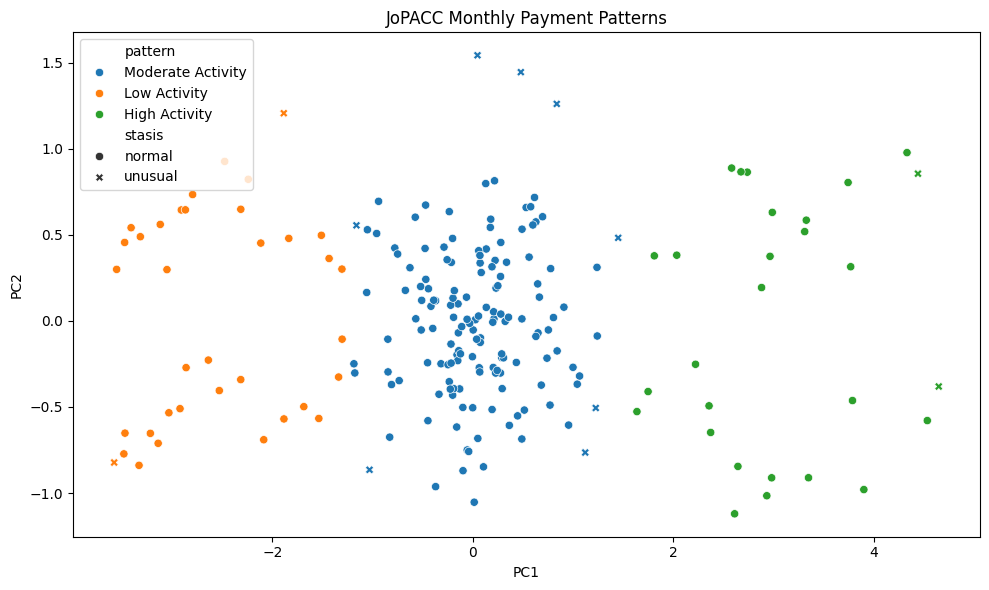

In [ ]:
# Finally we draw the clusters on the PCA plot. The colour shows which pattern the month was
# given, and the marker shape shows whether we flagged it as unusual.
pca_data["pattern"] = monthly["pattern"]
pca_data["stasis"] = monthly["stasis"]
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_data,
    x="PC1",
    y="PC2",
    hue="pattern",
    style="stasis",
    markers={"normal": "o", "unusual": "X"}
)
plt.title("JoPACC Monthly Payment Patterns")
plt.tight_layout()
plt.show()

In [ ]:
# And here we list the months that were marked as unusual.
unusual_months = monthly[monthly["stasis"] == "unusual"]
unusual_months[[
    "report_month",
    "system",
    "cluster",
    "pattern",
    "transactions_total",
    "transaction_value_jod",
    "stasis"
]]

,report_month,system,cluster,pattern,transactions_total,transaction_value_jod,stasis
42,2022-11-01,CliQ,3,Low Activity,985000,175000000,unusual
70,2025-03-01,CliQ,2,Moderate Activity,12110000,1560000000,unusual
84,2026-05-01,CliQ,1,High Activity,21430000,2130000000,unusual
95,2023-12-01,ECCU,2,Moderate Activity,577000,4440000000,unusual
142,2024-03-01,JoMoPay,2,Moderate Activity,3900000,400000000,unusual
155,2025-04-01,JoMoPay,2,Moderate Activity,6990000,469000000,unusual
168,2026-05-01,JoMoPay,1,High Activity,14980000,698000000,unusual
175,2023-04-01,eFAWATEERcom,3,Low Activity,3480000,991000000,unusual
177,2023-06-01,eFAWATEERcom,2,Moderate Activity,3650000,750000000,unusual
199,2025-04-01,eFAWATEERcom,2,Moderate Activity,6540000,1570000000,unusual
